In [13]:
import os
import struct
import random
import json
import csv
import time
import glob
import shutil
import re
from collections import Counter, defaultdict

import torch
import torchaudio
import torchaudio.transforms as T
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

# Kaggle Hardware & Path Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Processing hardware: {device.type.upper()}")

# INPUT: Assumes the dataset folder is attached directly in Kaggle
# UPDATE THIS PATH to match your exact Kaggle input directory name
DATASET_DIR = "/kaggle/input/datasets/cooldatascientist/caac-atc-fatigue-corpus"

# WORKING DIRECTORIES (Kaggle provides ~73GB of temporary space here)
CONT_SAMPLES_DIR = "/kaggle/temp/continuous_samples"
RAW_TENSOR_DIR = "/kaggle/temp/ATC_Raw_Audio_Tensors_NEW"
FEATURE_TENSOR_DIR = "/kaggle/temp/ATC_Spatial_Features_NEW"

ATC_FOLDERS = {
    "ATCs_1_speech": "ATC1", "ATCs_2": "ATC2",
    "ATCs_3_speech": "ATC3", "ATCs_4": "ATC4",
    "ATCs_5_speech": "ATC5", "ATCs_6_speech": "ATC6",
    "ATCs_7_speech": "ATC7",
}

# Standard splits for MDAN Architecture
SPLIT_MAP = {
    "ATC1": "train", "ATC2": "train", "ATC3": "train", "ATC4": "train", "ATC5": "train",
    "ATC6": "val", 
    "ATC7": "test"
}

LABEL_MAP = {"Ambiguous": 0, "Fatigue": 1, "Non-Fatigue": 2}
LABEL_PADDING = -1

TARGET_SR = 8000
WINDOW_SEC = 2.0
WINDOW_SAMPLES = int(TARGET_SR * WINDOW_SEC)

🚀 Processing hardware: CPU


In [9]:
def _parse_wav_header(raw_bytes):
    if raw_bytes[:4] != b'RIFF' or raw_bytes[8:12] != b'WAVE':
        raise ValueError("Not a valid WAV/RIFF file")

    fmt_tag    = struct.unpack_from('<H', raw_bytes, 20)[0]
    n_channels = struct.unpack_from('<H', raw_bytes, 22)[0]
    framerate  = struct.unpack_from('<I', raw_bytes, 24)[0]
    sampwidth  = struct.unpack_from('<H', raw_bytes, 34)[0] // 8

    offset = 12
    data_offset = data_size = None
    while offset < len(raw_bytes) - 8:
        cid = raw_bytes[offset:offset + 4]
        csz = struct.unpack_from('<I', raw_bytes, offset + 4)[0]
        if cid == b'data':
            data_offset = offset + 8
            data_size = csz
            break
        offset += 8 + csz

    if data_offset is None:
        raise ValueError("No 'data' chunk found")
    return fmt_tag, n_channels, framerate, sampwidth, data_offset, data_size

def _build_ulaw_table():
    table = []
    for u in range(256):
        u_val = (~u) & 0xFF
        sign = u_val & 0x80
        exponent = (u_val >> 4) & 0x07
        mantissa = u_val & 0x0F
        sample = ((mantissa << 1) + 33) << exponent
        sample -= 33
        table.append(-sample if sign else sample)
    return table

_ULAW_TABLE = _build_ulaw_table()

def get_duration(path):
    with open(path, 'rb') as fh:
        raw = fh.read(512)
    _, n_channels, framerate, sampwidth, _, data_size = _parse_wav_header(raw)
    sw = max(sampwidth, 1)
    return data_size / (framerate * n_channels * sw)

def read_wav(path):
    with open(path, 'rb') as fh:
        raw = fh.read()
    fmt_tag, n_channels, framerate, sampwidth, d_off, d_sz = _parse_wav_header(raw)
    data_bytes = raw[d_off:d_off + d_sz]

    if fmt_tag == 1:
        fmt_char = {1: 'B', 2: 'h', 4: 'i'}.get(sampwidth, 'h')
        n_vals = d_sz // max(sampwidth, 1)
        samples = list(struct.unpack_from(f'<{n_vals}{fmt_char}', data_bytes))
    elif fmt_tag == 7:
        samples = [_ULAW_TABLE[b] for b in data_bytes]
        sampwidth = 2
    else:
        raise ValueError(f"Unsupported format tag {fmt_tag}")
    return samples, framerate, n_channels, sampwidth

def write_wav(path, samples, framerate, n_channels=1, sampwidth=2):
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    data = struct.pack(f'<{len(samples)}h', *samples)
    with open(path, 'wb') as fh:
        fh.write(b'RIFF')
        fh.write(struct.pack('<I', 36 + len(data)))
        fh.write(b'WAVE')
        fh.write(b'fmt ')
        fh.write(struct.pack('<I', 16))
        fh.write(struct.pack('<H', 1))
        fh.write(struct.pack('<H', n_channels))
        fh.write(struct.pack('<I', framerate))
        fh.write(struct.pack('<I', framerate * n_channels * sampwidth))
        fh.write(struct.pack('<H', n_channels * sampwidth))
        fh.write(struct.pack('<H', sampwidth * 8))
        fh.write(b'data')
        fh.write(struct.pack('<I', len(data)))
        fh.write(data)

def to_mono_int16(samples, n_channels, sampwidth):
    if n_channels == 2:
        samples = [(samples[i] + samples[i + 1]) // 2 for i in range(0, len(samples) - 1, 2)]
    if sampwidth == 1:
        samples = [(s - 128) * 256 for s in samples]
    elif sampwidth == 4:
        samples = [s >> 16 for s in samples]
    return samples

def load_atc_samples(root_dir, min_duration=5.0):
    data = {}
    for folder, atc_id in ATC_FOLDERS.items():
        atc_path = os.path.join(root_dir, folder)
        if not os.path.isdir(atc_path): continue
        data[atc_id] = {'fatigue': [], 'nonfatigue': []}
        
        for cls in ('fatigue', 'nonfatigue'):
            cls_path = os.path.join(atc_path, cls)
            if not os.path.isdir(cls_path): continue
            for fname in sorted(os.listdir(cls_path)):
                if not fname.lower().endswith('.wav'): continue
                fpath = os.path.join(cls_path, fname)
                try:
                    if get_duration(fpath) >= min_duration:
                        data[atc_id][cls].append(fpath)
                except Exception as e:
                    pass
    return data

def make_chunk(clip_paths, target_sr=8000):
    combined = []
    for path in clip_paths:
        samples, sr, n_ch, sw = read_wav(path)
        samples = to_mono_int16(samples, n_ch, sw)
        if sr != target_sr:
            ratio = target_sr / sr
            n_out = int(len(samples) * ratio)
            samples = [samples[int(i / ratio)] for i in range(n_out)]
        combined.extend(samples)
    return combined, target_sr

class ContinuousSampleBuilder:
    def __init__(self, fatigue_clips, nonfatigue_clips, clips_per_chunk=3, target_sr=8000, random_generator=None):
        self.sr = target_sr
        self.random_gen = random_generator if random_generator else random.Random(42)
        f_chunks = [('F', make_chunk(fatigue_clips[i * clips_per_chunk:(i + 1) * clips_per_chunk], target_sr)[0]) for i in range(2)]
        nf_chunks = [('NF', make_chunk(nonfatigue_clips[i * clips_per_chunk:(i + 1) * clips_per_chunk], target_sr)[0]) for i in range(2)]
        all_chunks = f_chunks + nf_chunks
        self.random_gen.shuffle(all_chunks)

        self.combined_audio = []
        self.chunk_boundaries = []
        cursor = 0
        for cls, audio in all_chunks:
            start = cursor
            self.combined_audio.extend(audio)
            cursor += len(audio)
            self.chunk_boundaries.append((cls, start, cursor))

    @property
    def duration_sec(self):
        return len(self.combined_audio) / self.sr

def assign_window_label(win_start, win_end, chunk_boundaries):
    f_samples, nf_samples = 0, 0
    for cls, cs, ce in chunk_boundaries:
        overlap = max(0, min(win_end, ce) - max(win_start, cs))
        if cls == 'F': f_samples += overlap
        else: nf_samples += overlap
    if f_samples > 0 and nf_samples > 0: return LABEL_MAP["Ambiguous"]
    return LABEL_MAP["Fatigue"] if f_samples >= nf_samples else LABEL_MAP["Non-Fatigue"]

def segment_and_label(builder, window_size_sec=2.0):
    win_samples = int(window_size_sec * builder.sr)
    windows, start = [], 0
    while start + win_samples <= len(builder.combined_audio):
        end = start + win_samples
        label = assign_window_label(start, end, builder.chunk_boundaries)
        windows.append((start, end, label))
        start = end
    return windows, builder.combined_audio

def detect_transitions(labels, window_size_sec=2.0):
    state_names = {v: k for k, v in LABEL_MAP.items()}
    transitions, total_f_windows, prev = [], 0, None
    for i, lbl in enumerate(labels):
        if lbl == LABEL_PADDING: break
        if lbl == LABEL_MAP["Fatigue"]: total_f_windows += 1
        if prev is not None and lbl != prev:
            transitions.append((state_names[prev], state_names[lbl], i * window_size_sec))
        prev = lbl
    return {"transitions": transitions, "total_fatigue_sec": total_f_windows * window_size_sec}

In [12]:
print("=" * 70)
print(" 🎙️ ATC Continuous Speech Sample Creation")
print("=" * 70)

# 1. FIX: Redirect output to Kaggle's high-capacity temporary storage (~73GB free)
CONT_SAMPLES_DIR = "/kaggle/temp/continuous_samples"
os.makedirs(os.path.join(CONT_SAMPLES_DIR, "audio"), exist_ok=True)

atc_data = load_atc_samples(DATASET_DIR, min_duration=5.0)
random_gen = random.Random(42)

all_metadata = []
global_idx = 0
TARGET_SAMPLES = 2701 

for atc_id, clips in atc_data.items():
    f_pool, nf_pool = clips['fatigue'][:], clips['nonfatigue'][:]
    
    # Safety Check: Skip ATCs with absolutely zero valid clips in either category
    if len(f_pool) == 0 or len(nf_pool) == 0:
        print(f"⚠️ SKIP {atc_id}: Missing data (Fatigue: {len(f_pool)}, Non-Fatigue: {len(nf_pool)})")
        continue
        
    print(f"⚙️ Processing {atc_id}... (Target: {TARGET_SAMPLES})")
    # if len(f_pool) < 6 or len(nf_pool) < 6:
    #     print(f"   ↳ Note: Limited clips available (F: {len(f_pool)}, NF: {len(nf_pool)}). Reusing clips.")
    
    created = 0
    while created < TARGET_SAMPLES:
        # Use random_gen.choices (WITH replacement) to prevent the ValueError
        f_batch = random_gen.choices(f_pool, k=6)
        nf_batch = random_gen.choices(nf_pool, k=6)
        
        builder = ContinuousSampleBuilder(f_batch, nf_batch, 3, TARGET_SR, random_gen)
        windows, audio = segment_and_label(builder, WINDOW_SEC)
        label_seq = [lbl for (_, _, lbl) in windows]
        ts_info = detect_transitions(label_seq, WINDOW_SEC)
        
        # Save to the new high-capacity directory
        wav_path = os.path.join(CONT_SAMPLES_DIR, "audio", f"{atc_id}_sample_{global_idx:06d}.wav")
        write_wav(wav_path, audio, TARGET_SR)
        
        all_metadata.append({
            "sample_id": global_idx, "atc_id": atc_id, "file_path": wav_path,
            "duration_sec": round(builder.duration_sec, 2), "n_windows": len(windows),
            "n_fatigue_win": label_seq.count(LABEL_MAP["Fatigue"]),
            "n_nonfatigue_win": label_seq.count(LABEL_MAP["Non-Fatigue"]),
            "n_ambiguous_win": label_seq.count(LABEL_MAP["Ambiguous"]),
            "total_fatigue_sec": ts_info["total_fatigue_sec"],
            "transitions": ts_info["transitions"],
        })
        global_idx += 1
        created += 1

# Save Metadata
meta_path = os.path.join(CONT_SAMPLES_DIR, "metadata.json")
with open(meta_path, 'w') as fh:
    json.dump({"target_sr": TARGET_SR, "samples": all_metadata}, fh, indent=2)

print(f"✅ Created {global_idx} continuous samples in {CONT_SAMPLES_DIR}")

 🎙️ ATC Continuous Speech Sample Creation
⚙️ Processing ATC1... (Target: 2701)
⚙️ Processing ATC2... (Target: 2701)
⚙️ Processing ATC3... (Target: 2701)
⚙️ Processing ATC4... (Target: 2701)
⚙️ Processing ATC5... (Target: 2701)
⚙️ Processing ATC6... (Target: 2701)
⚙️ Processing ATC7... (Target: 2701)
✅ Created 18907 continuous samples in /kaggle/temp/continuous_samples


In [14]:
print("="*60)
print("✂️ 1D TENSOR SLICING & GLOBAL RANDOM ROUTING")
print("="*60)

AUDIO_DIR = os.path.join(CONT_SAMPLES_DIR, "audio")

def reconstruct_labels(metadata_item):
    n_windows = metadata_item["n_windows"]
    transitions = metadata_item["transitions"]
    labels = [None] * n_windows

    if not transitions:
        dominant = LABEL_MAP["Fatigue"] if metadata_item["n_fatigue_win"] > 0 else LABEL_MAP["Non-Fatigue"]
        return [dominant] * n_windows

    current_state = LABEL_MAP[transitions[0][0]]
    trans_idx = 0
    for i in range(n_windows):
        if trans_idx < len(transitions) and i * WINDOW_SEC >= transitions[trans_idx][2]:
            current_state = LABEL_MAP[transitions[trans_idx][1]]
            trans_idx += 1
        labels[i] = current_state
    return labels

# Re-load metadata
with open(os.path.join(CONT_SAMPLES_DIR, "metadata.json"), 'r') as f:
    metadata = json.load(f)["samples"]

# Set seed for reproducible splitting
random.seed(42)
split_options = ["train", "val", "test"]
split_weights = [0.70, 0.15, 0.15] # 70% train, 15% val, 15% test

for item in tqdm(metadata, desc="Slicing all sequences"):
    atc_id = item["atc_id"]
    
    # Randomly assign this specific audio sequence to a split
    split_name = random.choices(split_options, weights=split_weights, k=1)[0]
    
    out_folder = os.path.join(RAW_TENSOR_DIR, split_name, atc_id)
    os.makedirs(out_folder, exist_ok=True)
    
    sample_id = f"{item['sample_id']:06d}"
    wav_path = os.path.join(AUDIO_DIR, os.path.basename(item['file_path']))

    if not os.path.exists(wav_path): continue

    try:
        waveform, sr = torchaudio.load(wav_path)
    except: continue

    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)

    label_seq = reconstruct_labels(item)
    audio_chunks, valid_labels = [], []

    for i in range(item["n_windows"]):
        start_idx = i * WINDOW_SAMPLES
        end_idx = start_idx + WINDOW_SAMPLES
        chunk = waveform[:, start_idx:end_idx]

        if chunk.shape[1] == WINDOW_SAMPLES:
            audio_chunks.append(chunk)
            valid_labels.append(label_seq[i])

    if len(audio_chunks) == 0 or len(audio_chunks) != len(valid_labels): continue

    X_raw_seq = torch.stack(audio_chunks)
    y_seq = torch.tensor(valid_labels)

    torch.save(X_raw_seq, os.path.join(out_folder, f"X_raw_{sample_id}.pt"))
    torch.save(y_seq, os.path.join(out_folder, f"y_{sample_id}.pt"))

print("✅ Global 1D Tensor Extraction & Random Split Complete.")

✂️ 1D TENSOR SLICING & GLOBAL RANDOM ROUTING


Slicing all sequences:   0%|          | 0/18907 [00:00<?, ?it/s]

✅ Global 1D Tensor Extraction & Random Split Complete.


🔬 INTEGRITY TEST (Loading one sample into RAM)
✅ Found 18907 Audio sequences and 18907 Label sequences.
File Inspected: /kaggle/temp/ATC_Raw_Audio_Tensors_NEW/test/ATC1/X_raw_002514.pt
X_raw shape: torch.Size([35, 1, 16000]) -> [Sequence_Length, Channels, Samples]
y_label shape: torch.Size([35]) -> [Sequence_Length]
✅ Sequence lengths align perfectly.


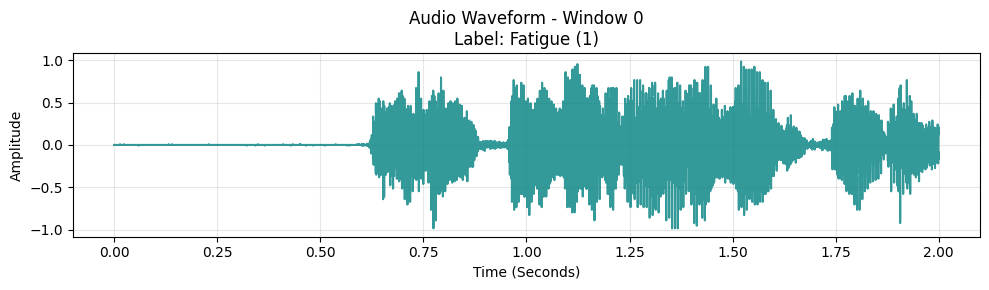

In [15]:
print("="*60)
print("🔬 INTEGRITY TEST (Loading one sample into RAM)")
print("="*60)

x_files = glob.glob(os.path.join(RAW_TENSOR_DIR, "**", "X_raw_*.pt"), recursive=True)
y_files = glob.glob(os.path.join(RAW_TENSOR_DIR, "**", "y_*.pt"), recursive=True)

print(f"✅ Found {len(x_files)} Audio sequences and {len(y_files)} Label sequences.")

if x_files:
    first_x_path = x_files[0]
    y_path = first_x_path.replace("X_raw_", "y_")
    
    if os.path.exists(y_path):
        X_sample = torch.load(first_x_path)
        y_sample = torch.load(y_path)
        
        print(f"File Inspected: {first_x_path.replace('/kaggle/working/', '')}")
        print(f"X_raw shape: {X_sample.shape} -> [Sequence_Length, Channels, Samples]")
        print(f"y_label shape: {y_sample.shape} -> [Sequence_Length]")
        
        assert X_sample.shape[0] == y_sample.shape[0], "CRITICAL ERROR: Sequence lengths mismatch!"
        print("✅ Sequence lengths align perfectly.")
        
        first_window_audio = X_sample[0, 0, :].numpy() 
        first_window_label = y_sample[0].item()
        label_map_reverse = {v: k for k, v in LABEL_MAP.items()}
        
        plt.figure(figsize=(10, 3))
        plt.plot(np.linspace(0, 2.0, len(first_window_audio)), first_window_audio, color='teal', alpha=0.8)
        plt.title(f"Audio Waveform - Window 0\nLabel: {label_map_reverse.get(first_window_label, 'Unknown')} ({first_window_label})")
        plt.xlabel("Time (Seconds)")
        plt.ylabel("Amplitude")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [16]:
print("="*60)
print("🌌 GPU SPATIAL FEATURE EXTRACTION (1D -> 2D Spectrograms)")
print("="*60)

# Init Mel Transform on GPU
mel_transform = T.MelSpectrogram(
    sample_rate=TARGET_SR,
    n_fft=512,
    hop_length=256,
    n_mels=128
).to(device)

amplitude_to_db = T.AmplitudeToDB().to(device)

processed_count = 0
for raw_file_path in tqdm(x_files, desc="Extracting 2D Tensors"):
    path_parts = raw_file_path.split(os.sep)
    file_name = path_parts[-1]
    atc_id = path_parts[-2]
    split_folder = path_parts[-3]
    
    sample_id = file_name.replace("X_raw_", "").replace(".pt", "")
    y_file_path = os.path.join(os.path.dirname(raw_file_path), f"y_{sample_id}.pt")
    
    out_dir = os.path.join(FEATURE_TENSOR_DIR, split_folder, atc_id)
    os.makedirs(out_dir, exist_ok=True)
    
    target_x_path = os.path.join(out_dir, f"X_spatial_{sample_id}.pt")
    target_y_path = os.path.join(out_dir, f"y_{sample_id}.pt")
    
    try:
        X_raw_seq = torch.load(raw_file_path).to(device)
    except: continue
    
    # GPU Math Execution
    mel_spec = mel_transform(X_raw_seq)
    log_mel = amplitude_to_db(mel_spec)
    
    # Push back to CPU for hard drive save
    torch.save(log_mel.cpu(), target_x_path)
    
    if os.path.exists(y_file_path):
        y_seq = torch.load(y_file_path)
        torch.save(y_seq, target_y_path)
        
    processed_count += 1

print(f"✅ Spatial Extraction Complete! Successfully extracted {processed_count} tensors.")

# CRITICAL CLEANUP: Free up space before Kaggle dataset upload constraints hit (~73GB limit)
print("🧹 Cleaning up raw audio files to free disk space...")
shutil.rmtree(CONT_SAMPLES_DIR, ignore_errors=True)
shutil.rmtree(RAW_TENSOR_DIR, ignore_errors=True)
print("✅ Space cleared.")

🌌 GPU SPATIAL FEATURE EXTRACTION (1D -> 2D Spectrograms)


Extracting 2D Tensors:   0%|          | 0/18907 [00:00<?, ?it/s]

✅ Spatial Extraction Complete! Successfully extracted 18907 tensors.
🧹 Cleaning up raw audio files to free disk space...
✅ Space cleared.


In [ ]:
# ====================================================
# SECURE KAGGLE DATASET UPLOAD
# ====================================================
import os
import json

KAGGLE_USERNAME = "<YOUR-KAGGLE-USERNAME>" 
KAGGLE_KEY = "<YOUR-KAGGLE-API-KEY>"

print("Authenticating Kaggle API...")
os.makedirs('/root/.kaggle', exist_ok=True)

api_token = {"username": KAGGLE_USERNAME, "key": KAGGLE_KEY}
with open('/root/.kaggle/kaggle.json', 'w') as file:
    json.dump(api_token, file)
os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("📝 Creating dataset metadata...")
dataset_metadata = {
    "title": "ATC Spatial Features 18k",
    "id": f"{KAGGLE_USERNAME}/atc-spatial-features-18k-NEW",
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ]
}

# Write the metadata directly to the target folder
metadata_path = os.path.join(FEATURE_TENSOR_DIR, "dataset-metadata.json")
with open(metadata_path, 'w') as f:
    json.dump(dataset_metadata, f, indent=4)

print("🚀 Initiating secure transfer to Kaggle Datasets...")
# Execute the creation command (bypassing the 'init' command)
!kaggle datasets create -p {FEATURE_TENSOR_DIR} --dir-mode zip

print("✅ Upload process finished. Check your Kaggle Datasets tab.")

Authenticating Kaggle API...
📝 Creating dataset metadata...
🚀 Initiating secure transfer to Kaggle Datasets...
Starting upload for file test.zip
100%|██████████████████████████████████████| 2.93G/2.93G [01:21<00:00, 38.8MB/s]
Upload successful: test.zip (3GB)
Starting upload for file train.zip
100%|██████████████████████████████████████| 13.8G/13.8G [05:30<00:00, 44.9MB/s]
Upload successful: train.zip (14GB)
Starting upload for file val.zip
100%|██████████████████████████████████████| 3.01G/3.01G [01:13<00:00, 43.7MB/s]
Upload successful: val.zip (3GB)
Your private Dataset is being created. Please check progress at https://www.kaggle.com/datasets/cooldatascientist/atc-spatial-features-18k-NEW
✅ Upload process finished. Check your Kaggle Datasets tab.
